Dataset extracted successfully.
Using dataset directory: human_action_dataset/Human Action Recognition
Found 18011 files belonging to 2 classes.
Using 14409 files for training.
Found 18011 files belonging to 2 classes.
Using 3602 files for validation.

Action classes: ['test', 'train']
Number of classes: 2


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,018 (429.76 KB)

 Trainable params: 110,018 (429.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 548s 1s/step - accuracy: 0.6960 - loss: 0.6196 - val_accuracy: 0.7118 - val_loss: 0.6013
Epoch 2/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 544s 1s/step - accuracy: 0.6966 - loss: 0.6165 - val_accuracy: 0.7118 - val_loss: 0.6020
Epoch 3/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 550s 1s/step - accuracy: 0.6966 - loss: 0.6154 - val_accuracy: 0.7118 - val_loss: 0.6027
Epoch 4/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 548s 1s/step - accuracy: 0.6966 - loss: 0.6148 - val_accuracy: 0.7118 - val_loss: 0.6016

Model Evaluation
----------------
Validation loss: 0.6013
Validation accuracy: 71.18%

Classification Report:
              precision    recall  f1-score   support

        test       0.00      0.00      0.00      1038
       train       0.71      1.00      0.83      2564

    accuracy                           0.71      3602
   macro avg       0.36      0.50      0.42      3602
weighted avg       0.51      0.71      0.59      3602

Confusion Matrix:
[[   0 1038]
 [   0 2564]]


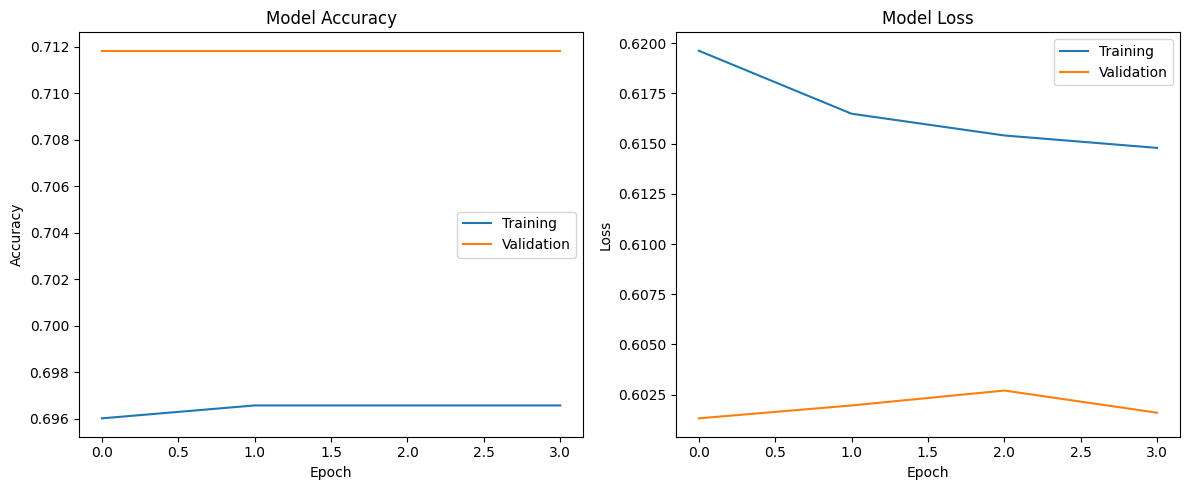


Model saved as human_action_model.keras


In [3]:
import os
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping


ZIP_PATH = "archive.zip"
DATA_DIR = "human_action_dataset"

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15
SEED = 42

tf.keras.utils.set_random_seed(SEED)


if not os.path.isdir(DATA_DIR):
    os.makedirs(DATA_DIR, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
        zip_file.extractall(DATA_DIR)

    print("Dataset extracted successfully.")


image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

def find_class_directory(root):
    """Find a directory whose immediate subfolders
    contain images for different action classes."""

    root = Path(root)

    for folder in [root] + list(root.rglob("*")):
        if not folder.is_dir():
            continue

        class_folders = [
            item for item in folder.iterdir()
            if item.is_dir()
            and any(
                file.suffix.lower() in image_extensions
                for file in item.rglob("*")
                if file.is_file()
            )
        ]

        if len(class_folders) >= 2:
            return folder

    return None


class_dir = find_class_directory(DATA_DIR)

if class_dir is None:
    raise ValueError(
        "Could not find folders containing separate action "
        "classes. Check the dataset structure. If it contains "
        "a CSV file with labels, the loading code must be adapted."
    )

print("Using dataset directory:", class_dir)


train_data = tf.keras.utils.image_dataset_from_directory(
    str(class_dir),
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    str(class_dir),
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_data.class_names
num_classes = len(class_names)

print("\nAction classes:", class_names)
print("Number of classes:", num_classes)


AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(AUTOTUNE)
validation_data = validation_data.prefetch(AUTOTUNE)


model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),


    layers.Rescaling(1.0 / 255),


    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),


    layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),


    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


loss, accuracy = model.evaluate(validation_data, verbose=0)

print("\nModel Evaluation")
print("----------------")
print(f"Validation loss: {loss:.4f}")
print(f"Validation accuracy: {accuracy * 100:.2f}%")


actual_labels = []
predicted_labels = []

for images, labels in validation_data:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    actual_labels.extend(labels.numpy())
    predicted_labels.extend(predictions)

actual_labels = np.array(actual_labels)
predicted_labels = np.array(predicted_labels)

print("\nClassification Report:")
print(classification_report(
    actual_labels,
    predicted_labels,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(actual_labels, predicted_labels))


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


model.save("human_action_model.keras")
print("\nModel saved as human_action_model.keras")


def predict_action(image_path):
    """Predict the action category for a single image."""

    if not os.path.isfile(image_path):
        print("Image file not found:", image_path)
        return

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    best_index = int(np.argmax(probabilities))

    print("\nPrediction Result")
    print("-----------------")
    print("Predicted action:", class_names[best_index])
    print(f"Confidence: {probabilities[best_index] * 100:.2f}%")

